# Saturn on spatial RNA + ATAC of a demyelinating lesion

This tutorial runs the Saturn workflow on one real section: mouse brain 10 days after a lysolecithin (LPC) injection, profiled by
DBiT ARC-seq (GEO samples GSM9247593 for RNA and GSM9249009 for ATAC, Fig. 2 of the Saturn paper). The section has 8,180 spots.
We cut it down to a field of view of 3,425 spots that holds the lesion and a distal white-matter focus of microglia.

We are going to choose the spots, build one target per modality, fit Saturn, check the fit against the published one, call
domains along each axis, annotate them, screen and fit features along each axis, ask whether a feature follows its own axis or
the other one, compute TF activity along the axes, compare genes with their cis peaks, and ask what the cross pathways explain.

The notebook runs in about 8 min on a CPU with 8 threads for the fit. Install Saturn from the repository root with
`pip install -e ".[gaston]"`; the ATAC and motif steps also need `snapatac2`, `pyjaspar` and `pyfaidx`.

## Data preprocessing

A CPU fit depends on the seed and on the thread count, so `OMP_NUM_THREADS` has to be set before `torch` is imported. The published
fit used 8 threads.

Every input is read from one workspace folder, `WORK` (by default `saturn_workspace` next to the notebook, or the folder named by
`SATURN_WORKSPACE`). The list of files and where each comes from is in `docs/tutorials/workspace_files.json`. The published
results sit in `WORK/published` and are only read, for the comparisons below.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "8"

import json
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import snapatac2 as snap
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, parallel_config
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components
from scipy.stats import spearmanr, mannwhitneyu

import saturn
from saturn.theme import MODALITY, REGION, ANCHOR
saturn.theme.set_theme(8)                      # the colours and fonts of the paper figures

WORK = Path(os.environ.get("SATURN_WORKSPACE", "saturn_workspace"))   # the workspace folder: inputs, and published results in published/
RES = WORK / "published"
STEPS = Path(saturn.__file__).parents[2] / "reproducibility/steps"
FRAG = WORK / "GSM9249009_07_LPC10S1_atac_fragments.tsv.gz"
GTF = WORK / "gencode.vM25.primary_chr.annotation.gtf"
FASTA = WORK / "mm10.fa"
OUT = Path("outputs/tutorial_lpc_rna_atac"); OUT.mkdir(parents=True, exist_ok=True)

published = dict(np.load(RES / "targets_lpc10_fov.npz", allow_pickle=True))      # published targets, for the comparisons only
fig2 = json.load(open(RES / "fig2_part2.json"))   # numbers printed on the published figure
fig2e = json.load(open(RES / "fig2_part1.json"))["features"]

The two AnnData objects were built from the GEO files: RNA keeps in-tissue spots and genes seen in at least 10 spots, ATAC counts
fragments on the ENCODE mouse cCREs and keeps peaks seen in at least 1% of barcodes, and both keep the spots they share. The script
is `reproducibility/steps/fig2_arcseq_lpc10.py` and it takes about 3 min.

The spot order matters, because it enters the targets and the fit. The original script took it from `list(set(a) & set(b))`, which
differs in every Python process, so a rebuild has to read the published order from `steps/fig2_lpc10s1_obs_order.txt`. The saved
objects already have that order, which we check here.

In [2]:
rna = ad.read_h5ad(WORK / "arcseq_LPC10S1_rna_adata.h5ad")
atac = ad.read_h5ad(WORK / "arcseq_LPC10S1_atac_adata.h5ad")
order = (STEPS / "fig2_lpc10s1_obs_order.txt").read_text().split()
print("RNA", rna.shape, " ATAC", atac.shape)
print("spot order equals the pinned order:", list(rna.obs_names) == order, list(atac.obs_names) == order)

RNA (8180, 15799)  ATAC (8180, 68021)
spot order equals the pinned order: True True


## Choosing the spots

Spot selection changes the fit more than any model setting. On this section, a cortex subset gave R2 0.13 to 0.30 for RNA, and the
field of view below gives 0.64. The aim is to make the biology of interest the main variance of the selected spots.

Saturn has no function for this step because it depends on the question. Here we score microglia on the DBiT RNA, pooled over each
spot's 13 nearest spots as a Poisson z against the section-wide rate. Spots with z > 3 outside the cortex clusters are grouped into
connected components, and the two largest are the lesion and the distal white-matter focus. The cortex clusters are CellCharter
clusters 1, 5 and 2 at K = 10; the labels are an input (`LPC10_cc_labels.csv`), since they come from an unseeded scVI run.

In [3]:
xy_all = np.asarray(rna.obsm["spatial"], float)
X_all = sp.csr_matrix(rna.X)
vn = rna.var_names.astype(str)
lib_all = np.asarray(X_all.sum(1)).ravel().clip(1)

def score(genes):
    return np.asarray(X_all[:, vn.get_indexer([g for g in genes if g in vn])].sum(1)).ravel().astype(float)

mg, my = score(["Itgax", "Itgam", "Cd68", "Trem2", "Aif1", "Cx3cr1", "P2ry12"]), score(["Mbp", "Plp1", "Mog"])
nb = cKDTree(xy_all).query(xy_all, k=13)[1]
rate = mg.sum() / lib_all.sum()
zmg = (mg[nb].sum(1) - rate * lib_all[nb].sum(1)) / np.sqrt(np.maximum(rate * lib_all[nb].sum(1), 1e-9))
myz = np.log1p(my / lib_all * 1e4); myz = (myz - myz.mean()) / myz.std()

cc = pd.read_csv(WORK / "LPC10_cc_labels.csv", index_col=0)["cc_K10"].astype(int).values
cc_all = cc[cKDTree(np.load(WORK / "LPC10_coords.npy")).query(xy_all, k=1)[1]]
cortex = np.isin(cc_all, [1, 5, 2])

def components(idx):
    """connected components of the spots idx on a 6-nearest-neighbour graph, largest first"""
    knn = cKDTree(xy_all[idx]).query(xy_all[idx], k=7)[1]
    adj = sp.csr_matrix((np.ones(knn[:, 1:].size), (np.repeat(np.arange(len(idx)), 6), knn[:, 1:].ravel())), shape=(len(idx), len(idx)))
    cl = connected_components(adj + adj.T, directed=False)[1]
    return [idx[cl == k] for k in np.argsort(-np.bincount(cl))]

comp = components(np.where((zmg > 3) & ~cortex)[0])
lesion, distal = components(comp[0])[0], components(comp[1])[0]
print(f"microglia-positive spots outside the cortex: {((zmg > 3) & ~cortex).sum()}; lesion {len(lesion)}, distal focus {len(distal)}")

microglia-positive spots outside the cortex: 771; lesion 560, distal focus 211


The field of view is the joint bounding box of the two foci, padded by 3 spot pitches, minus the cortex clusters. All reductions
below are recomputed on these spots, because a reduction made on the whole section carries the variance of the whole section.

FOV spots 3425 {'other': 2654, 'lesion': 560, 'distal_WM': 211}
same spots as published: True ; same lesion and focus: True True ; max|diff| of the microglia z 0


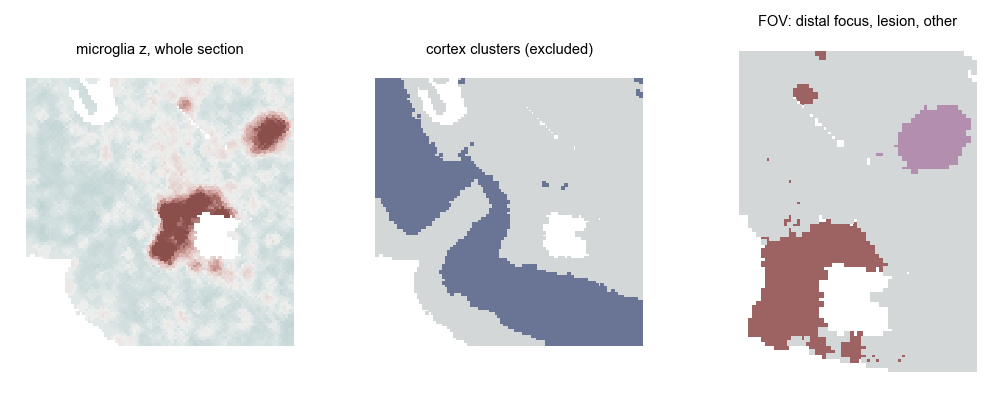

In [4]:
pitch = np.median(np.diff(np.unique(xy_all[:, 0])))
foci = np.r_[lesion, distal]
lo, hi = xy_all[foci].min(0) - 3 * pitch, xy_all[foci].max(0) + 3 * pitch
fov = np.all((xy_all >= lo) & (xy_all <= hi), axis=1) & ~cortex
idx = np.where(fov)[0]

xy = xy_all[idx]
bc = rna.obs_names[idx].astype(str)
region = np.where(np.isin(idx, lesion), "lesion", np.where(np.isin(idx, distal), "distal_WM", "other"))
ann = dict(microglia_z=zmg[idx], myelin_z=myz[idx], dist_to_lesion=cKDTree(xy_all[lesion]).query(xy, k=1)[0])
print("FOV spots", len(idx), pd.Series(region).value_counts().to_dict())

P = np.load(RES / "lpc10_fov.npz", allow_pickle=True)
print("same spots as published:", (P["fov_mask"].astype(bool) == fov).all(), "; same lesion and focus:",
      set(P["lesion"].tolist()) == set(lesion.tolist()), set(P["distal"].tolist()) == set(distal.tolist()),
      f"; max|diff| of the microglia z {np.abs(P['zmg'] - zmg).max():.2g}")

fig, ax = plt.subplots(1, 3, figsize=(8.5, 3))
saturn.plotting.spatial(ax[0], xy_all, np.clip(zmg, -5, 15), "microglia z, whole section", center=0)
saturn.plotting.spatial(ax[1], xy_all, cortex.astype(int), "cortex clusters (excluded)", discrete=True,
                        colors=[REGION["other"], ANCHOR["slate"]])
saturn.plotting.spatial(ax[2], xy, pd.factorize(region, sort=True)[0], "FOV: distal focus, lesion, other", discrete=True,
                        colors=[REGION["distal WM focus"], REGION["lesion"], REGION["other"]])
plt.show()

## Building the targets

Saturn fits low-dimensional continuous targets with a mean squared error, one target per modality, each scaled globally.

**RNA.** `rna_glmpc_real` runs Poisson GLM-PCA over 3,000 Pearson-residual HVGs. It starts from an unseeded `np.random` draw, so
each run returns different factors and the fit follows them. We run it to show the call and how far a new draw lands from the
published one, and then load the published `Y_RNA`, so that everything below can be checked against the paper.

In [5]:
X = sp.csr_matrix(rna.X)[idx]
genes = np.array(rna.var_names.astype(str))

Y_fresh, info_R = saturn.rna_glmpc_real(X, K=10)
depth_R = info_R["depth"]                                        # counts over the genes detected in at least 1% of spots
pin = np.load(STEPS / "fig2_glmpc_published.npz", allow_pickle=True)
assert (pin["barcodes"].astype(str) == bc).all()
Y_R = pin["Y_RNA"]

best_r = np.abs(np.corrcoef(Y_fresh.T, Y_R.T)[:10, 10:]).max(0)
print("method", info_R["method"], " penalty", info_R.get("penalty"))
print("best |r| of each published GLM-PC with this new draw:", np.round(best_r, 2).tolist())
print(f"depth max|diff| with the published depth_RNA {np.abs(depth_R - published['depth_RNA']).max():.3g}")

      glmpca converged with penalty=1


method glmpca  penalty 1
best |r| of each published GLM-PC with this new draw: [0.98, 0.74, 0.83, 0.68, 0.49, 0.48, 0.52, 0.59, 0.57, 0.72]
depth max|diff| with the published depth_RNA 0


**ATAC.** The ATAC target uses 5 kb tiles from the fragments of these spots, not the peak matrix. `atac_spectral` selects 250,000
tiles, computes a SnapATAC2 spectral embedding with 15 components and drops component 1, which follows depth. The fragment file is
read for these barcodes only.

In [6]:
tmp = OUT / "fov_tiles.h5ad"
data = snap.pp.import_fragments(str(FRAG), chrom_sizes=snap.genome.mm10, file=str(tmp), sorted_by_barcode=False, min_num_fragments=0,
                                whitelist=set(bc) | {f"{b}-1" for b in bc})
snap.pp.add_tile_matrix(data, bin_size=5000)
tiles = data.to_memory(); data.close(); os.remove(tmp)
tiles.obs_names = [str(b)[:-2] if str(b).endswith("-1") else str(b) for b in tiles.obs_names]
tiles = tiles[list(bc)].copy()

Y_A, info_A = saturn.atac_spectral(tiles, n_comps=15)
Y_A = Y_A.astype(np.float32)
depth_A = info_A["depth"].astype(np.float32)
del tiles

print("tile target", Y_A.shape, " |Spearman| of the dropped component with depth", np.round(info_A["depth_corr_dropped"], 2).tolist())
print(f"max|diff| with the published Y_ATAC {np.abs(Y_A - published['Y_ATAC']).max():.3g}")

tile target (3425, 7)  |Spearman| of the dropped component with depth [0.99]
max|diff| with the published Y_ATAC 0


`check_target` reports how strongly each leading component follows depth and whether it is spatially structured. A component that
mainly follows depth should be removed before the fit. `zscore_coords` scales x and y by one common value, which keeps the geometry.

In [7]:
coords_z = saturn.zscore_coords(xy)
print(f"max|diff| with the published coords_z {np.abs(coords_z - published['coords_z']).max():.3g}")
print("RNA ", saturn.check_target(Y_R, depth=depth_R, coords=xy))
print("ATAC", saturn.check_target(Y_A, depth=depth_A, coords=xy))

max|diff| with the published coords_z 0
RNA  {'var_share': [0.3391, 0.1522, 0.0958, 0.0942, 0.0861, 0.0671, 0.0523, 0.0455, 0.0447, 0.023], 'elbow': None, 'depth_corr': [0.172, 0.063, 0.137, 0.071, 0.06], 'depth_leak': 0.172, 'moran': 0.784}
ATAC {'var_share': [0.5265, 0.1701, 0.0932, 0.0706, 0.0638, 0.0384, 0.0374], 'elbow': None, 'depth_corr': [0.069, 0.456, 0.071, 0.095, 0.078], 'depth_leak': 0.456, 'moran': 0.769}


## Fitting Saturn

`saturn.fit` trains the model for each seed and keeps the seed with the lowest whole-section loss. The defaults of `train_saturn` are
the settings used in the paper, so only the seed, the thread count and the depth (for the depth check) are given. Training has three
stages: cross pathways off, cross pathways on, and restarts of each head that are accepted only if the fit on held-out spots improves.

In [8]:
targets, modalities = [Y_R, Y_A], ["RNA", "ATAC"]
res = saturn.fit(targets, coords_z, modalities, seeds=[42], threads=8, depth=dict(RNA=depth_R, ATAC=depth_A))
res.save(OUT, coords=xy, barcodes=list(bc))
print("best seed", res.best_seed, " whole-section fit", np.round(res.fit_all_by_seed, 4).tolist())

best seed 42  whole-section fit [0.6833]


## Comparing with the published fit

The same targets, seed and thread count should return the published axes. We read the published `axes.csv` and print the largest
difference and the correlation per axis.

In [9]:
pub_axes = pd.read_csv(RES / "lpc10_fov/axes.csv", index_col=0)
assert (pub_axes.index.astype(str) == bc).all()
pd.DataFrame([dict(axis=m, max_abs_diff=np.abs(res.axes[:, k] - pub_axes[f"d_{m}"].values).max(),
                   abs_r=abs(np.corrcoef(res.axes[:, k], pub_axes[f"d_{m}"].values)[0, 1])) for k, m in enumerate(modalities)])

,axis,max_abs_diff,abs_r
0,RNA,2.220446e-16,1.0
1,ATAC,2.220446e-16,1.0


## Checking the fit

Before any biology, look at the variance explained (`r2`), the cross-pathway share (`coupling`), the correlation of each axis with
depth (`axis_depth_corr`) and between the axes (`axis_axis_corr`). The coupling is not identifiable when the axes correlate above
about 0.8. Entry `[m, k]` of the coupling matrix is the share of the predicted variance of modality `m` that is carried by axis `k`.
It is a variance share, not a causal arrow.

The axis-axis Spearman here is -0.08. The published `summary.json` holds +0.08, while the Spearman computed from the published axes is
-0.08, so that file has the size but not the sign. The figure reports the Pearson r, -0.25. Either way the two axes are far from
collinear, so the coupling can be read. The depth correlations in that file (0.09, 0.053) also differ from those computed from the published
axes (0.117, 0.121), which equal the ones here; the file was not written by the current code, and the figures do not read these values.

The sign of an isodepth is arbitrary. `saturn.orient` flips axes to match a reference; here we keep the fitted signs, so that the
domain indices match the published tables.

The later cells read the axes from a float64 text file, as the published run did. `res.save` writes `axes.csv` from the float32 axes,
which rounds them more; that changes the third decimal of a few slopes below.

       full  own_axis_only  other_axes_only
RNA   0.643          0.365            0.338
ATAC  0.674          0.498            0.209
published full R2 {'RNA': 0.643, 'ATAC': 0.674}

coupling (row = modality, column = axis)
         RNA   ATAC
RNA   0.541  0.459
ATAC  0.259  0.741

axis vs depth, |Spearman| {'RNA': 0.117, 'ATAC': 0.121}  published {'RNA': 0.09, 'ATAC': 0.053}
computed from the published axes {'RNA': 0.117, 'ATAC': 0.121}
axis vs axis, Spearman -0.08  summary.json 0.08  Spearman of the published axes -0.080
axis vs axis, Pearson -0.252  figure -0.252
max|diff| of the saved axes with the published file 0


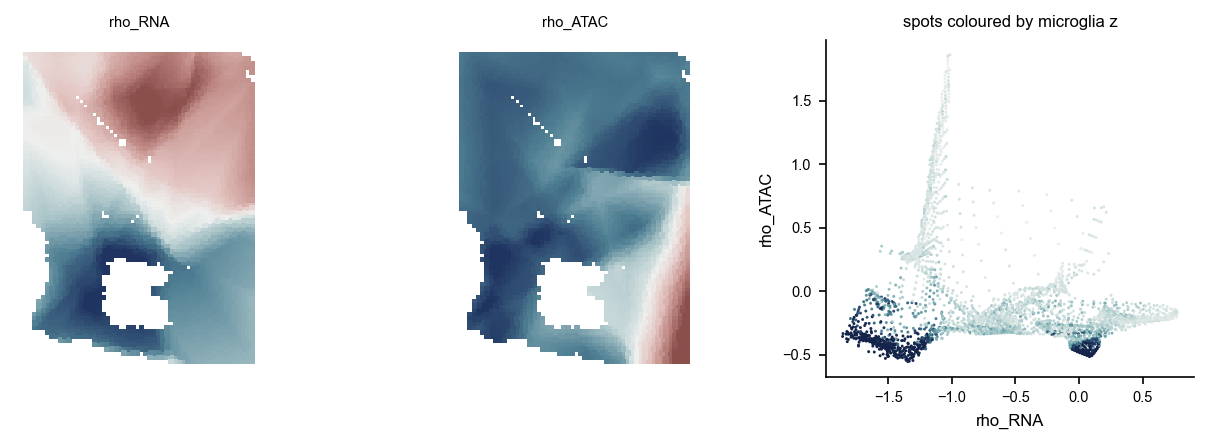

In [10]:
pub_sum = json.load(open(RES / "lpc10_fov/summary.json"))
print(pd.DataFrame(res.r2).T.round(3))
print("published full R2", {m: round(pub_sum["R2_whole"][m]["full"], 3) for m in modalities})
print("\ncoupling (row = modality, column = axis)\n", pd.DataFrame(res.coupling, modalities, modalities).round(3))
print("\naxis vs depth, |Spearman|", {k: round(v, 3) for k, v in res.axis_depth_corr.items()},
      " published", {k: round(v, 3) for k, v in pub_sum["axis_depth_corr"].items()})
print("computed from the published axes", {m: round(abs(spearmanr(pub_axes[f"d_{m}"], published[f"depth_{m}"]).statistic), 3) for m in modalities})
print("axis vs axis, Spearman", res.axis_axis_corr[0][1], " summary.json", pub_sum["axis_axis_corr"][0][1],
      f" Spearman of the published axes {spearmanr(pub_axes.d_RNA, pub_axes.d_ATAC).statistic:.3f}")
print(f"axis vs axis, Pearson {np.corrcoef(res.axes.T)[0, 1]:.3f}  figure {fig2['r_rhoRNA_rhoATAC']:.3f}")

pd.DataFrame(np.c_[xy, res.axes], columns=["x", "y", "d_RNA", "d_ATAC"], index=bc).to_csv(OUT / "axes_float64.csv")
saved = pd.read_csv(OUT / "axes_float64.csv", index_col=0)
d_R, d_A = saved.d_RNA.values, saved.d_ATAC.values
print(f"max|diff| of the saved axes with the published file {max(np.abs(d_R - pub_axes.d_RNA.values).max(), np.abs(d_A - pub_axes.d_ATAC.values).max()):.3g}")
fig, ax = plt.subplots(1, 3, figsize=(8.5, 3))
saturn.plotting.spatial(ax[0], xy, d_R, "rho_RNA")
saturn.plotting.spatial(ax[1], xy, d_A, "rho_ATAC")
ax[2].scatter(d_R, d_A, s=2, c=ann["microglia_z"], cmap="saturn_seq_r", vmin=-3, vmax=10, lw=0, rasterized=True)
ax[2].set(xlabel="rho_RNA", ylabel="rho_ATAC", title="spots coloured by microglia z")
plt.tight_layout(); plt.show()

Where do the two foci sit on each axis? We turn each axis into a percentile, with the lesion at the low end, and compare the lesion
with the distal focus (the AUC is 0.5 when the two overlap).

In [11]:
rows = []
for k, m in enumerate(modalities):
    v = res.axes[:, k] if np.median(res.axes[region == "lesion", k]) < np.median(res.axes[:, k]) else -res.axes[:, k]
    pct = (np.argsort(np.argsort(v)) + 0.5) / len(v) * 100
    u = mannwhitneyu(v[region == "lesion"], v[region == "distal_WM"]).statistic / ((region == "lesion").sum() * (region == "distal_WM").sum())
    rows.append(dict(axis=m, lesion=np.median(pct[region == "lesion"]), distal_focus=np.median(pct[region == "distal_WM"]),
                     other=np.median(pct[region == "other"]), AUC=max(u, 1 - u), published_AUC=fig2["lesion_vs_distal_auc"][m]["auc"]))
pd.DataFrame(rows).round(3)

,axis,lesion,distal_focus,other,AUC,published_AUC
0,RNA,9.285,77.387,54.307,0.995,0.995
1,ATAC,13.898,6.905,59.066,0.723,0.723


rho_RNA places the lesion and the distal focus at opposite ends (median percentiles 9 and 77, AUC 0.995). rho_ATAC places both at the same
end (14 and 7, AUC 0.723). This suggests that the RNA axis follows distance from the lesion, while the ATAC axis follows a chromatin
state that the two foci share.

## Domains along each axis

Each modality is segmented on its own axis with its own targets. `choose_k` takes the elbow of the error curve of GASTON's dynamic
programme, `gaston_domains` assigns the spots, and `boundaries` returns the contour levels for maps. The published figures use the
elbow: K = 3 for RNA and K = 2 for ATAC.

K, RNA axis 3 [1235, 1202, 988]  ATAC axis 2 [1343, 2082]
published K 3 2


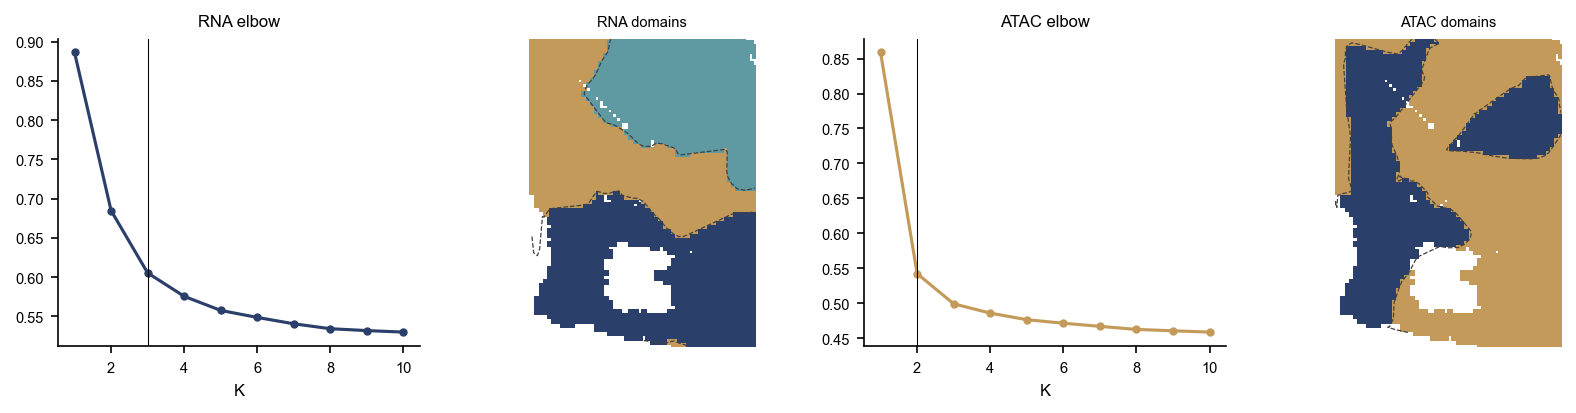

In [12]:
k_R, curve_R = saturn.domains.choose_k(d_R, Y_R)
k_A, curve_A = saturn.domains.choose_k(d_A, Y_A)
lab_R = saturn.domains.gaston_domains(d_R, Y_R, n_domains=k_R)
lab_A = saturn.domains.gaston_domains(d_A, Y_A, n_domains=k_A)
bnd_R, bnd_A = saturn.domains.boundaries(d_R, lab_R), saturn.domains.boundaries(d_A, lab_A)
print("K, RNA axis", k_R, np.bincount(lab_R).tolist(), " ATAC axis", k_A, np.bincount(lab_A).tolist())
elbow = json.load(open(RES / "domain_k_elbow/k_elbow.json"))
print("published K", elbow["fig2|RNA"], elbow["fig2|ATAC"])

fig, ax = plt.subplots(1, 4, figsize=(11, 2.8))
ax[0].plot(range(1, len(curve_R) + 1), curve_R, "o-", ms=3, c=MODALITY["RNA"]); ax[0].axvline(k_R, c="k", lw=.5); ax[0].set(title="RNA elbow", xlabel="K")
saturn.plotting.spatial(ax[1], xy, lab_R, "RNA domains", discrete=True, contour_d=d_R, bnds=bnd_R)
ax[2].plot(range(1, len(curve_A) + 1), curve_A, "o-", ms=3, c=MODALITY["ATAC"]); ax[2].axvline(k_A, c="k", lw=.5); ax[2].set(title="ATAC elbow", xlabel="K")
saturn.plotting.spatial(ax[3], xy, lab_A, "ATAC domains", discrete=True, contour_d=d_A, bnds=bnd_A)
plt.tight_layout(); plt.show()

## Domain annotation and markers

`annotate_counts` returns one row per domain: size, position on the axis, median depth, composition of the annotations passed through
`cats` and `conts`, top markers, and how many of the 500 most-counted features keep a slope inside the domain. With `gtf`, ATAC
markers are written as the nearest gene, the first letter of the peak class (`p` for promoter or proximal enhancer, `l` for long-distance)
with the distance to the TSS, and the log2 fold change. `gene_level` sums the peaks into their nearest gene. Name a domain from all of these
columns. Here 42% of the spots of RNA domain 0 are lesion spots, with a mean microglia z of 5.25, and Apoe and Ctsd are among its markers; domain 1
has the highest myelin score with Mbp and Plp1; domain 2 has Meg3 and Ntng1 and holds the distal focus. On the ATAC axis, domain 0 has a mean
microglia z of 6.83 and holds spots from both foci.

In [13]:
A = sp.csr_matrix(atac.X)[idx]
peaks = np.array(atac.var_names.astype(str))
lib_R, lib_A = np.asarray(X.sum(1)).ravel().clip(1), np.asarray(A.sum(1)).ravel().clip(1)
cats = dict(region=region, cellcharter=cc_all[idx])

names_R = {0: "lesion core", 1: "white matter", 2: "thalamic & periventricular"}
names_A = {0: "inflammatory chromatin", 1: "parenchymal"}
tab_R = saturn.annotate.annotate_counts(X, genes, lab_R, d_R, "RNA", depth=depth_R, cats=cats, conts=ann, labels=names_R)
tab_A = saturn.annotate.annotate_counts(A, peaks, lab_A, d_A, "ATAC", depth=depth_A, cats=cats, conts=ann, gtf=GTF, labels=names_A)
pd.set_option("display.max_colwidth", 90)
tab_R

,modality,domain,label,n_spots,isodepth,median_depth,region,cellcharter,microglia_z,myelin_z,dist_to_lesion,gradient_feats,markers
0,RNA,0,lesion core,1235,"[-1.86, -1.01]",776.0,"{""distal_WM"": 0.0, ""lesion"": 0.42, ""other"": 0.58}","{""0"": 0.49, ""3"": 0.02, ""6"": 0.05, ""7"": 0.33, ""8"": 0.11, ""9"": 0.0}",5.250,-0.079,168.787,391,Apoe(+0.9); Phactr1(+1.3); Ctsd(+1.2); Pde10a(+1.6); Meis2(+1.9); Rarb(+2.0); Cacna2d3...
1,RNA,1,white matter,1202,"[-1.01, -0.06]",1003.0,"{""distal_WM"": 0.0, ""lesion"": 0.02, ""other"": 0.98}","{""0"": 0.0, ""3"": 0.15, ""6"": 0.62, ""7"": 0.02, ""8"": 0.21, ""9"": 0.0}",-0.061,0.785,244.627,328,Ttr(+1.0); Mbp(+1.5); Plp1(+1.4); Fth1(+1.4); Ptgds(+1.9); Mobp(+1.5); Enpp2(+1.0); Tr...
2,RNA,2,thalamic & periventricular,988,"[-0.06, 0.77]",863.5,"{""distal_WM"": 0.21, ""lesion"": 0.01, ""other"": 0.78}","{""0"": 0.09, ""3"": 0.38, ""6"": 0.02, ""7"": 0.03, ""8"": 0.04, ""9"": 0.44}",1.824,-0.020,591.811,371,Meg3(+1.1); Ntng1(+3.0); Lsamp(+1.0); Gm32647(+3.5); Nxph1(+2.2); Snhg11(+0.9); Celf4(...


In [14]:
tab_A

,modality,domain,label,n_spots,isodepth,median_depth,region,cellcharter,microglia_z,myelin_z,dist_to_lesion,gradient_feats,markers,gene_level
0,ATAC,0,inflammatory chromatin,1343,"[-0.56, -0.26]",8325.0,"{""distal_WM"": 0.16, ""lesion"": 0.34, ""other"": 0.5}","{""0"": 0.38, ""3"": 0.24, ""6"": 0.29, ""7"": 0.0, ""8"": 0.06, ""9"": 0.02}",6.829,0.433,245.208,110,"Gtpbp4(p+16kb, +0.9); Gm18604(p+2kb, +0.7); Gm23935(p+0kb, +1.0); Limd1(p-17kb, +0.7);...",Gtpbp4(+0.9); Gm44086(+1.4); Inpp5d(+1.3); A630001O12Rik(+1.0); Tgfbr1(+1.1); Vsir(+1....
1,ATAC,1,parenchymal,2082,"[-0.26, 1.86]",7569.5,"{""distal_WM"": 0.0, ""lesion"": 0.05, ""other"": 0.95}","{""0"": 0.09, ""3"": 0.12, ""6"": 0.2, ""7"": 0.23, ""8"": 0.16, ""9"": 0.19}",-0.460,0.118,364.020,110,"Gm10222(p+0kb, +1.4); Gm9075(l+27kb, +1.5); Gm10722(p-0kb, +1.5); Gm10717(p-1kb, +1.4)...",Gm10222(+1.4); Gse1(+0.9); Adgrb1(+1.2); Gm13090(+1.2); Peg3(+1.3); Arc(+1.4); Phyhip(...


The published table `domain_annotation.csv` was written before K was chosen by the elbow, at K = 4 on both axes. To compare with it we
run the same call at K = 4. Column `gradient_feats` and the marker strings should be the same.

In [15]:
lab4_R = saturn.domains.gaston_domains(d_R, Y_R, n_domains=4)
lab4_A = saturn.domains.gaston_domains(d_A, Y_A, n_domains=4)
pub_dom = pd.read_csv(RES / "lpc10_fov_domains/domain_annotation.csv")
t4 = pd.concat([saturn.annotate.annotate_counts(X, genes, lab4_R, d_R, "RNA", depth=depth_R),
                saturn.annotate.annotate_counts(A, peaks, lab4_A, d_A, "ATAC", depth=depth_A, gtf=GTF)], ignore_index=True)
print("n_spots equal", (t4.n_spots == pub_dom.n_spots).all(), "; isodepth equal", (t4.isodepth == pub_dom.isodepth).all(),
      "; gradient_feats equal", (t4.gradient_feats.astype(str) + "/500" == pub_dom.gradient_feats).all(),
      "; markers equal", (t4.markers == pub_dom.markers).all(), "; median depth max|diff|", np.abs(t4.median_depth.astype(int) - pub_dom.median_depth).max())
print("ATAC gene-level markers equal", (t4.gene_level[4:].values == pub_dom.gene_level[4:].values).all())

n_spots equal True ; isodepth equal True ; gradient_feats equal True ; markers equal True ; median depth max|diff| 0
ATAC gene-level markers equal True


## Which features are functions of the axis

`annotate.screen` fits each candidate feature per domain with the likelihood of the modality, keeps a slope only when GASTON's
likelihood-ratio test passes at p < 0.1, and ranks by the number of sloped domains and the R2 against binned observed values. We keep
the settings of the paper: 1,500 genes with at least 200 counts in 30 bins, and 6,000 peaks with at least 100 counts in 20 bins.

The screen is a single loop over features, so here it runs on chunks of 250 features in 16 processes. Pass the full library through
`lib` so that a chunk uses the same exposure as the whole matrix.

In [16]:
def screen_chunks(M, names, lab, d, lib, n_top, min_count, n_bins, chunk=250, n_jobs=16):
    tot = np.asarray(M.sum(0)).ravel().astype(float)
    cand = np.argsort(-tot)[:n_top]; cand = cand[tot[cand] >= min_count]
    parts = [cand[i:i + chunk] for i in range(0, len(cand), chunk)]
    with parallel_config("loky", inner_max_num_threads=1):       # one BLAS thread per process, or the processes compete for cores
        out = Parallel(n_jobs=n_jobs)(delayed(saturn.annotate.screen)(M[:, p], names[p], lab, d, lib=lib, n_top=len(p), min_count=0, n_bins=n_bins)
                                      for p in parts)
    return pd.concat([o[0] for o in out]).drop(columns="_i").sort_values(["n_sloped_domains", "R2"], ascending=False).reset_index(drop=True)

scr_R = screen_chunks(X, genes, lab_R, d_R, lib_R, 1500, 200, 30)
scr_A = screen_chunks(A, peaks, lab_A, d_A, lib_A, 6000, 100, 20)
print(f"genes: {(scr_R.n_sloped_domains >= 2).sum()} of {len(scr_R)} sloped in >= 2 of {k_R} domains")
print(f"peaks: {(scr_A.n_sloped_domains >= 2).sum()} of {len(scr_A)} sloped in >= 2 of {k_A} domains")
scr_R.head(8)

genes: 988 of 1500 sloped in >= 2 of 3 domains
peaks: 347 of 6000 sloped in >= 2 of 2 domains


,feature,counts,n_sloped_domains,R2,slopes
0,Ptgds,4801,3,0.945,"[1.549, 0.111, -1.953]"
1,Unc5c,1247,3,0.895,"[0.593, -0.929, 2.225]"
2,Pcsk1n,2125,3,0.893,"[1.727, -0.414, 1.823]"
3,Tcf7l2,713,3,0.889,"[-1.756, 1.501, 2.198]"
4,Syn2,1096,3,0.881,"[1.506, -0.43, 2.611]"
5,Apod,2347,3,0.880,"[1.767, -0.812, -2.594]"
6,Zfhx3,1531,3,0.877,"[-2.102, 1.124, 1.667]"
7,Nxph1,901,3,0.873,"[-0.68, -0.563, 2.879]"


In [17]:
near_g, near_d = saturn.annotate.nearest_gene(peaks, GTF)
pos = {p: i for i, p in enumerate(peaks)}
scr_A["nearest_gene"] = [near_g[pos[p]] for p in scr_A.feature]
scr_A["kb_to_TSS"] = [round(near_d[pos[p]] / 1000, 1) for p in scr_A.feature]
scr_A.head(8)

,feature,counts,n_sloped_domains,R2,slopes,nearest_gene,kb_to_TSS
0,chr11:115189319-115189658,277,2,0.952,"[-2.874, -2.092]",Nat9,1.6
1,chr6:120473516-120473866,263,2,0.882,"[-3.433, -0.843]",Il17ra,10.4
2,chr17:36231390-36231692,4015,2,0.879,"[-1.249, -0.278]",Gm18604,2.1
3,chr11:83640203-83640535,259,2,0.860,"[-6.248, -0.765]",Rpl9-ps1,-5.3
4,chr11:118363069-118363418,311,2,0.847,"[-4.168, -0.914]",Timp2,7.5
5,chr19:10025513-10025841,257,2,0.846,"[-3.063, -0.94]",Fads3,-15.9
6,chr13:9011605-9011864,7563,2,0.845,"[-2.675, -0.092]",Gtpbp4,15.7
7,chr14:25473063-25473234,251,2,0.843,"[-7.164, -0.614]",Gm47921,-6.9


The published screens (`gene_screen.csv`, `peak_screen.csv`) are also at K = 4, so we repeat the screen at K = 4 for the comparison.

In [18]:
scr4_R = screen_chunks(X, genes, lab4_R, d_R, lib_R, 1500, 200, 30)
scr4_A = screen_chunks(A, peaks, lab4_A, d_A, lib_A, 6000, 100, 20)
for name, t, f in (("genes", scr4_R, "gene_screen.csv"), ("peaks", scr4_A, "peak_screen.csv")):
    p = pd.read_csv(RES / "lpc10_fov_marker_functions" / f).set_index("feature").loc[t.feature]
    sl = np.array(t.slopes.tolist()); sp_ = np.array([json.loads(s) for s in p.slopes])   # 3 and 2 decimals: at most 0.005 is rounding
    print(f"{name}: {len(t)} vs {len(p)} screened; n_sloped equal {(t.n_sloped_domains.values == p.n_sloped_domains.values).all()}; "
          f"R2 max|diff| {np.abs(t.R2.values - p.R2.values).max():.3g}; slopes max|diff| {np.abs(sl - sp_).max():.3g}")

genes: 1500 vs 1500 screened; n_sloped equal True; R2 max|diff| 0; slopes max|diff| 0.005
peaks: 6000 vs 6000 screened; n_sloped equal True; R2 max|diff| 0; slopes max|diff| 0.005


## Feature functions along each axis

`fit_poisson` fits GASTON's per-domain Poisson regression for chosen features, and `function_figure` draws one row per feature: the
axis, the domains, the raw rate, the fitted rate and the fitted function. Fig. 2e shows two genes on rho_RNA and two peaks on rho_ATAC.
`binned_r2` gives the R2 printed on the figure, in 30 bins for RNA and 20 for ATAC. `function_figure` always uses 25 bins for
the R2 in its titles, so those differ slightly.

Trem2: sloped in 2/3 domains, R2 0.576, published 0.576
Mbp: sloped in 3/3 domains, R2 0.748, published 0.748


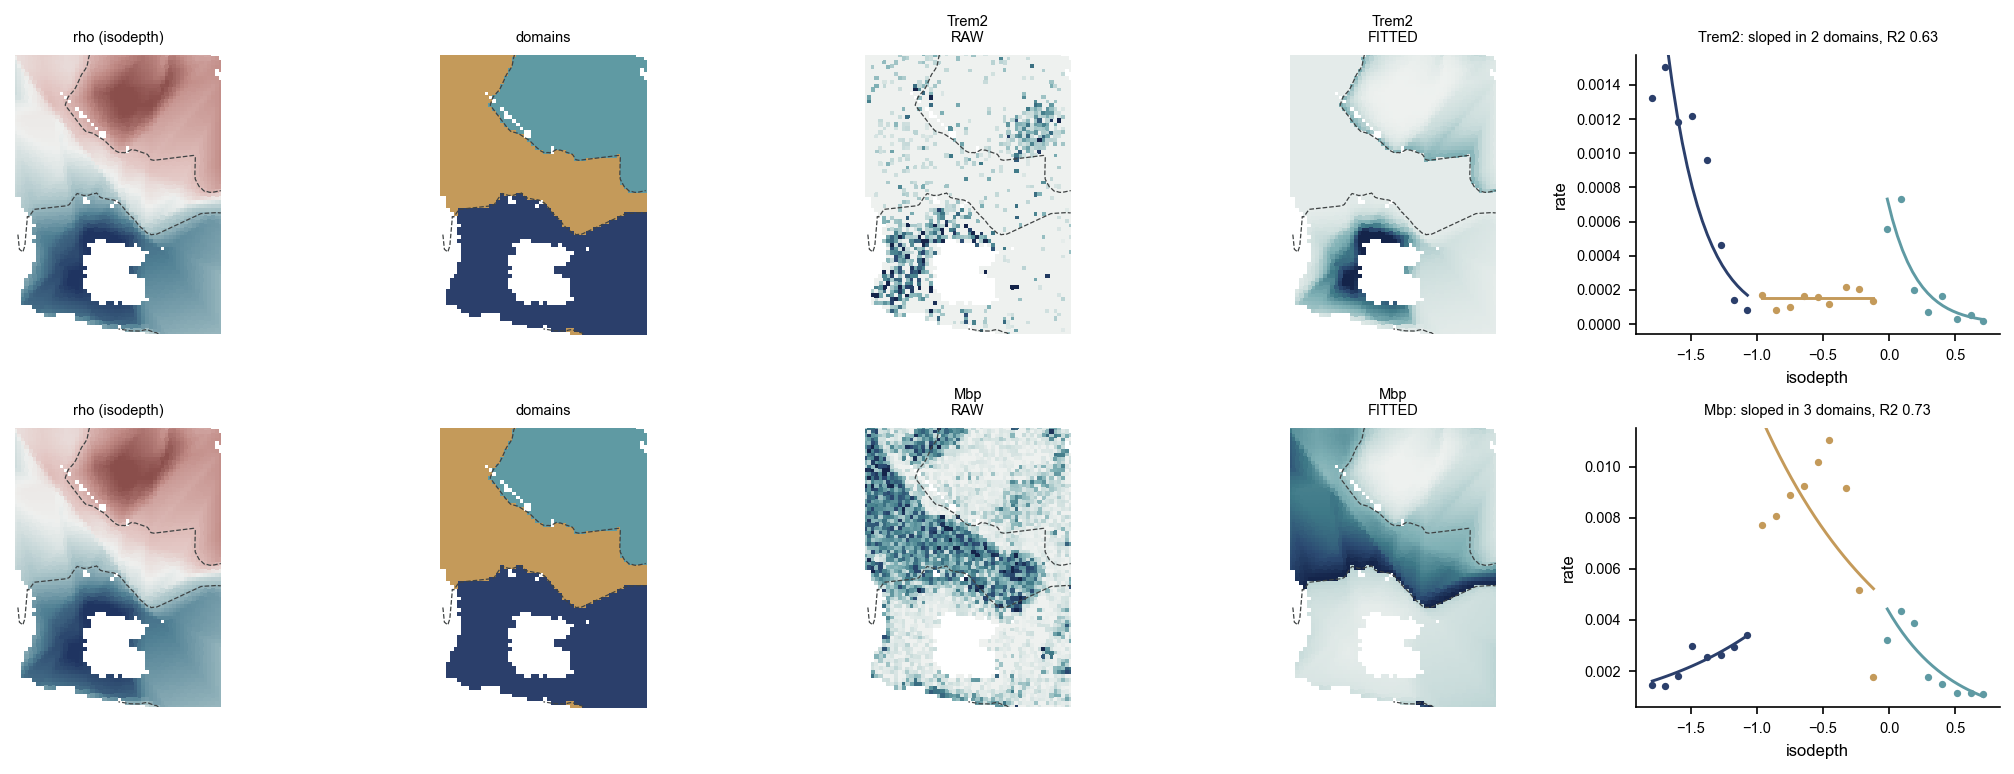

In [19]:
pw = saturn.piecewise

def feature_rows(M, names, feats, lab, d, lib, bnds, n_bins, pub_names):
    cols = [int(np.where(names == f)[0][0]) for f in feats]
    C = np.asarray(M[:, cols].todense(), float)
    slope, inter = pw.fit_poisson(C, lib, lab, d)
    for i, f in enumerate(feats):
        r2 = pw.binned_r2(C[:, i], d, lab, slope[i], inter[i], n_bins, lib=lib, link="log")[0]
        print(f"{f}: sloped in {pw.n_sloped(slope)[i]}/{lab.max() + 1} domains, R2 {r2:.3f}, published {fig2e[pub_names[i]]['R2']}")
    return saturn.plotting.function_figure(xy, d, lab, C, slope, inter, np.array(feats), range(len(feats)), bnds=bnds, lib=lib, link="log", unit="rate")

fig = feature_rows(X, genes, ["Trem2", "Mbp"], lab_R, d_R, lib_R, bnd_R, 30, ["Trem2", "Mbp"])
plt.show()

chr7:30412652-30413002: sloped in 2/2 domains, R2 0.688, published 0.688
chr2:91084599-91084795: sloped in 2/2 domains, R2 0.794, published 0.794


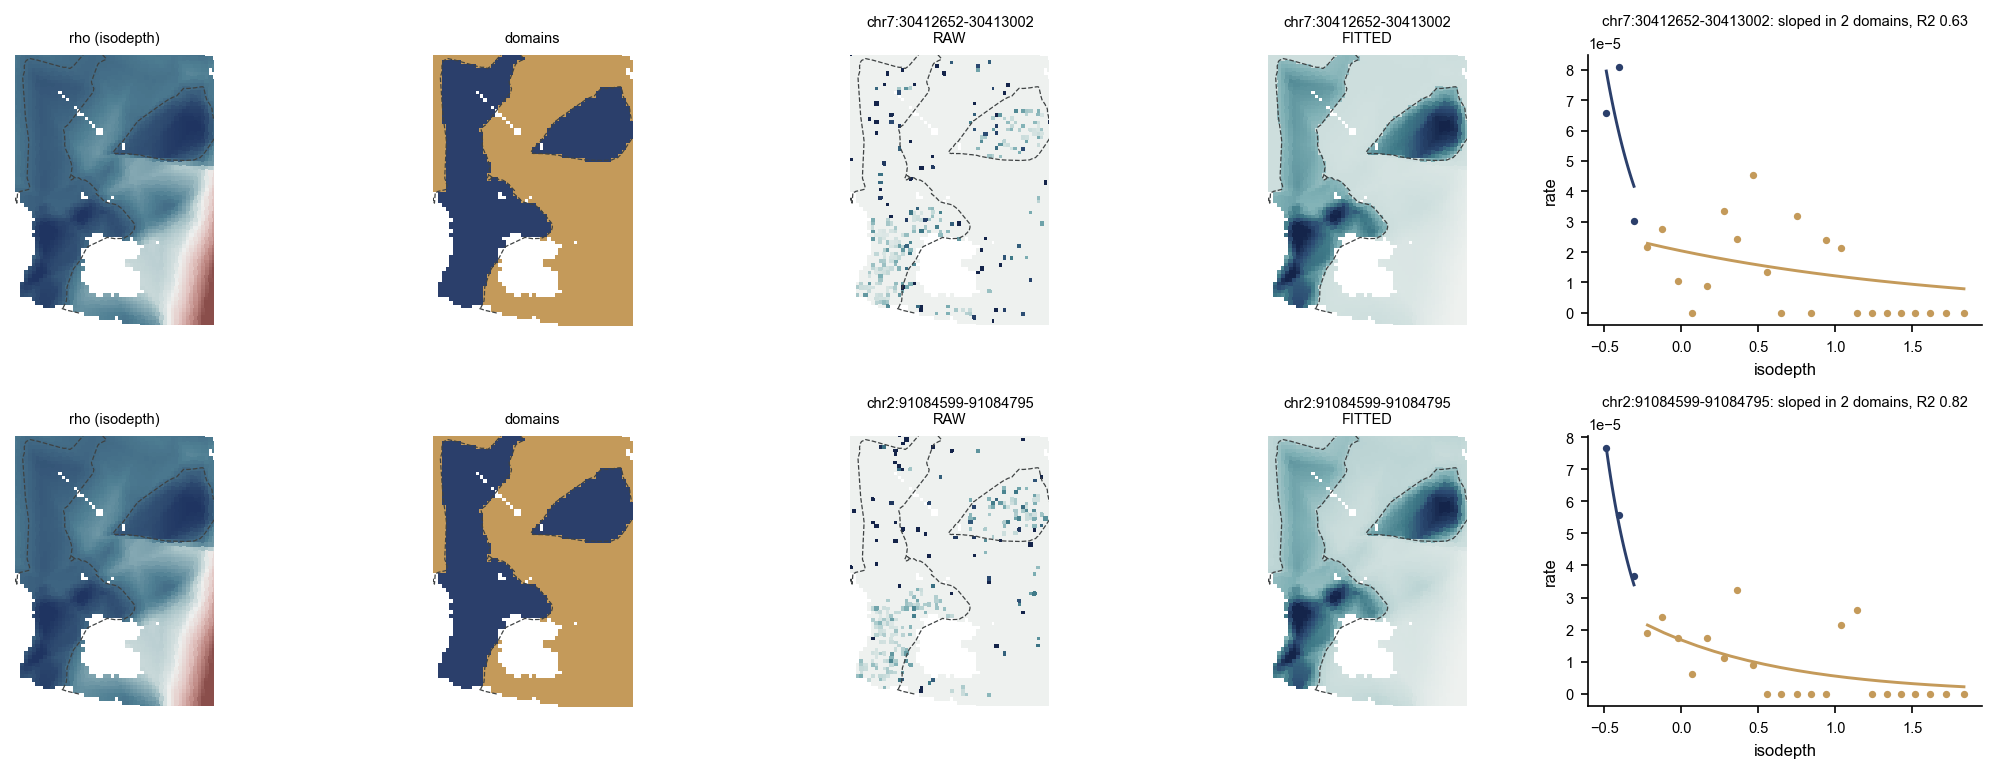

In [20]:
fig = feature_rows(A, peaks, ["chr7:30412652-30413002", "chr2:91084599-91084795"], lab_A, d_A, lib_A, bnd_A, 20, ["Tyrobp promoter", "Spi1 +2 kb enhancer"])
plt.show()

The same calls draw the top rows of the screen. Pick the columns from the names in the table. The row index of the `screen` table is the rank,
and the slopes it returns are in candidate order, so `top.index` cannot be used to index them.

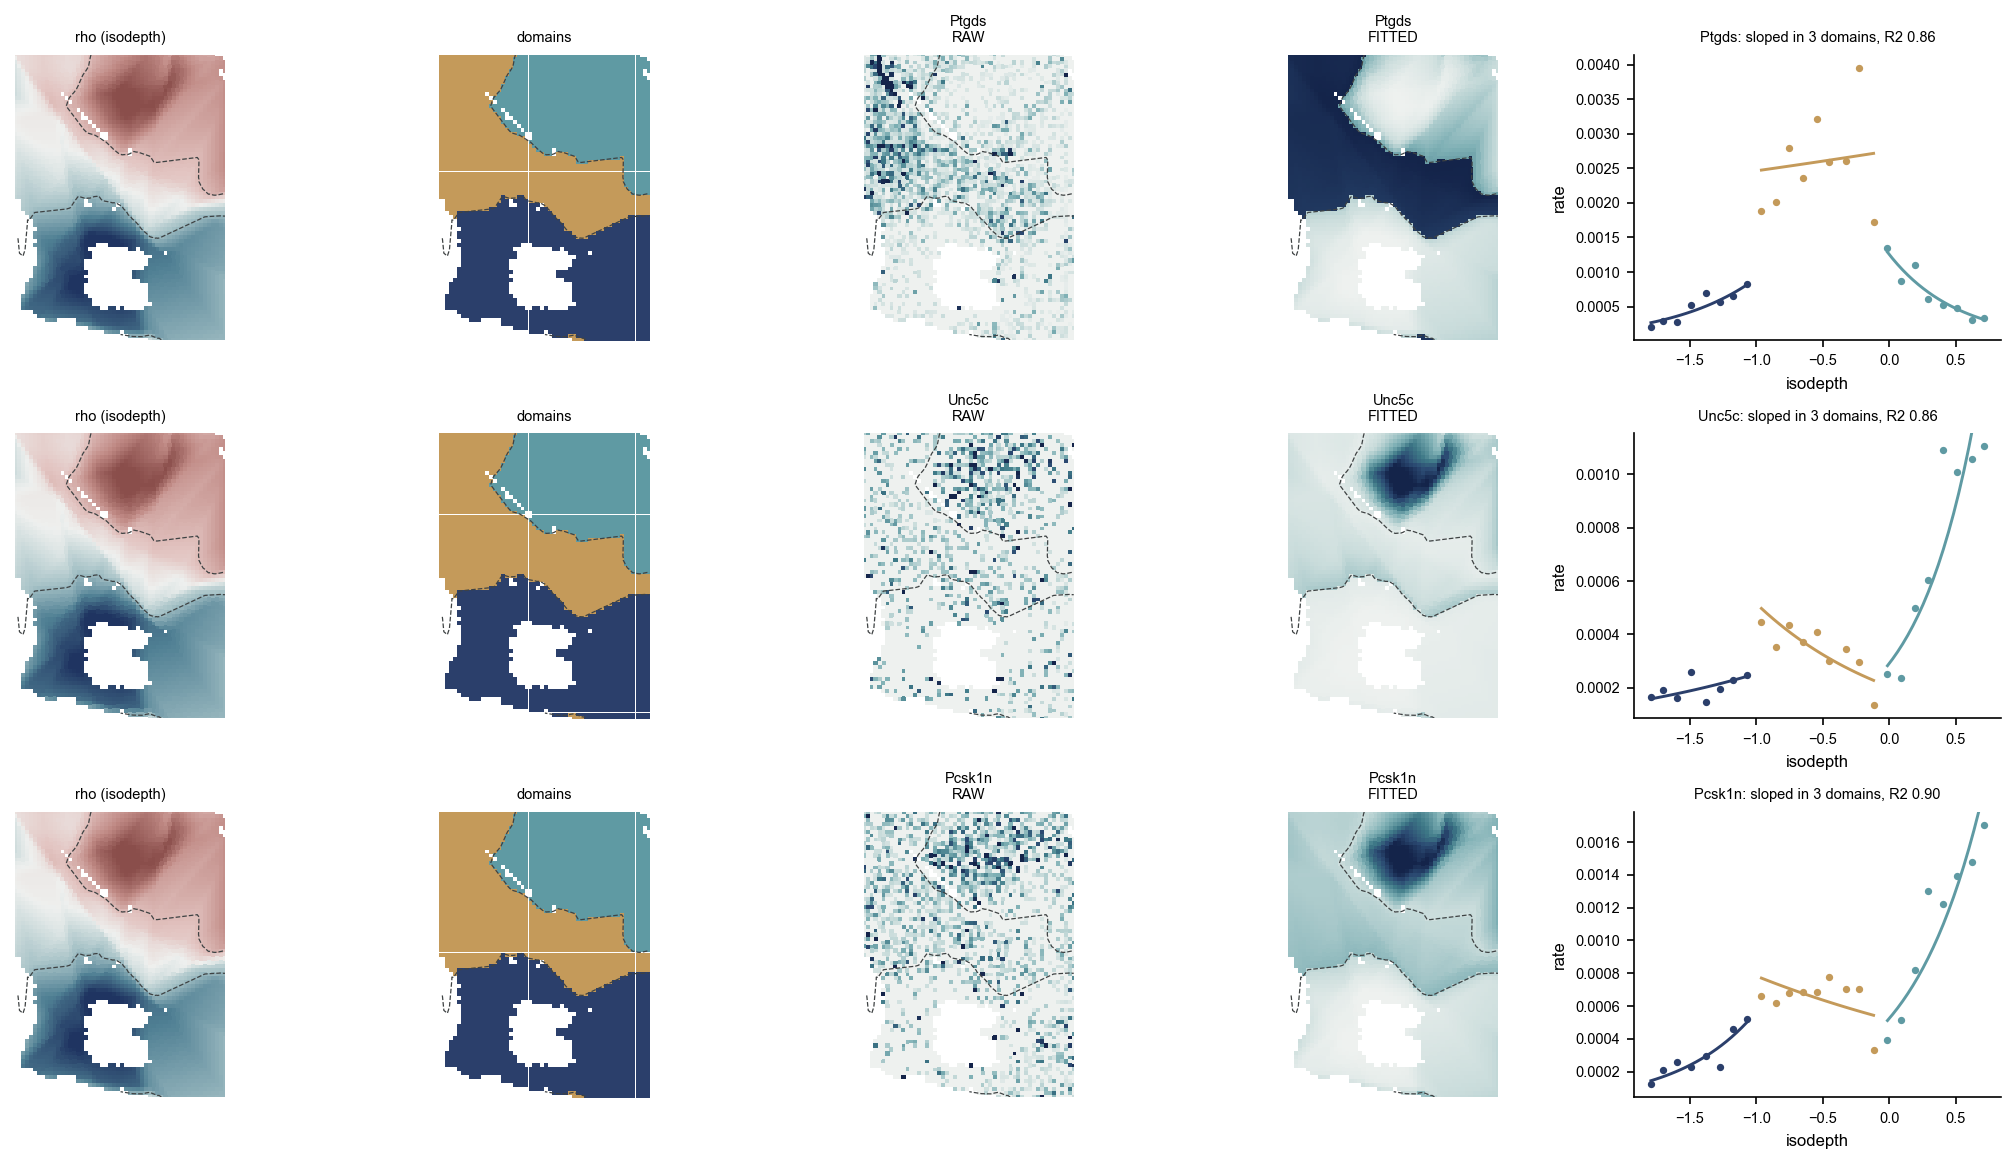

In [21]:
top = scr_R[scr_R.n_sloped_domains >= 2].head(3).feature.tolist()
cols = [int(np.where(genes == f)[0][0]) for f in top]
C = np.asarray(X[:, cols].todense(), float)
slope, inter = pw.fit_poisson(C, lib_R, lab_R, d_R)
fig = saturn.plotting.function_figure(xy, d_R, lab_R, C, slope, inter, np.array(top), range(3), bnds=bnd_R, lib=lib_R, link="log", unit="rate")
plt.show()

## Own axis or cross axis

`crossterm.own_vs_cross` asks, for each feature, how well its own axis and the other axis fit it, each per domain with a Gaussian
fit, on k-NN smoothed, z-scored log1p CP10k from `cis.smoothed_logcpm`. It splits the joint R2 into a part only the own axis carries,
a part only the cross axis carries, and a shared part.

In [22]:
g_top = np.argsort(-np.asarray(X.sum(0)).ravel().astype(float))[:1500]
p_top = np.argsort(-np.asarray(A.sum(0)).ravel().astype(float))[:2000]
G_s, P_s = saturn.cis.smoothed_logcpm(X, g_top, xy, 15), saturn.cis.smoothed_logcpm(A, p_top, xy, 15)

ovc_R = saturn.crossterm.own_vs_cross(G_s, d_R, lab_R, d_A, lab_A); ovc_R.insert(0, "feature", genes[g_top])
ovc_A = saturn.crossterm.own_vs_cross(P_s, d_A, lab_A, d_R, lab_R); ovc_A.insert(0, "feature", peaks[p_top])
print(pd.DataFrame({"genes on rho_RNA": ovc_R[["R2_own", "R2_cross", "R2_joint", "unique_own", "unique_cross", "shared"]].median(),
                    "peaks on rho_ATAC": ovc_A[["R2_own", "R2_cross", "R2_joint", "unique_own", "unique_cross", "shared"]].median()}).T.round(3))
print("\ngenes with the largest part only rho_ATAC carries")
ovc_R.sort_values("unique_cross", ascending=False).head(6)[["feature", "R2_own", "R2_cross", "R2_joint", "unique_own", "unique_cross", "shared"]]

                   R2_own  R2_cross  R2_joint  unique_own  unique_cross  \
genes on rho_RNA    0.150     0.079     0.183       0.077         0.021   
peaks on rho_ATAC   0.148     0.067     0.163       0.089         0.011   

                   shared  
genes on rho_RNA    0.054  
peaks on rho_ATAC   0.056  

genes with the largest part only rho_ATAC carries


,feature,R2_own,R2_cross,R2_joint,unique_own,unique_cross,shared
578,Tyrobp,0.2167,0.6072,0.6179,0.0108,0.4012,0.2060
430,Trem2,0.4081,0.6973,0.7819,0.0846,0.3739,0.3235
226,Ctsz,0.4157,0.6943,0.7844,0.0901,0.3687,0.3256
332,Sirpa,0.4195,0.6199,0.7344,0.1146,0.3149,0.3049
138,Sparc,0.2512,0.5262,0.5607,0.0345,0.3095,0.2167
540,Itgb5,0.4116,0.6116,0.7180,0.1065,0.3064,0.3052


For the median gene the own axis carries more than the cross axis (0.150 against 0.079), and the same holds for peaks (0.148 against 0.067).
The genes with the largest part that only rho_ATAC carries include Tyrobp and Trem2, which suggests that this microglial programme follows the
chromatin axis in both foci.

The published `own_vs_cross.csv` is again at K = 4 on both axes, so the comparison repeats the call at K = 4.

In [23]:
pub_ovc = pd.read_csv(RES / "lpc10_fov_own_vs_cross/own_vs_cross.csv")
for m, Y_s, f, a, b, la, lb in (("RNA", G_s, genes[g_top], d_R, d_A, lab4_R, lab4_A), ("ATAC", P_s, peaks[p_top], d_A, d_R, lab4_A, lab4_R)):
    t = saturn.crossterm.own_vs_cross(Y_s, a, la, b, lb)
    p = pub_ovc[pub_ovc.modality == m]
    c = ["R2_own", "R2_cross", "R2_joint", "unique_own", "unique_cross", "shared"]
    print(f"{m}: same features {(p.feature.values == f).all()}; max|diff| {np.abs(t[c].values - p[c].values).max():.3g}")

RNA: same features True; max|diff| 0


ATAC: same features True; max|diff| 0


## TF activity along the axes

`saturn.tfactivity` computes chromVAR-style TF activity with isodepth bins in place of metacells. We take the 12,000 most-counted peaks
and scan them with JASPAR 2022 motifs for TFs of five lineages (`jaspar_pwms`, `peak_sequences`, `scan_motifs`); a peak is a hit when its
score is in the top 1% for that TF. `background_sets` picks 50 background peak sets for each TF, matched on GC content and accessibility.

In [24]:
PANEL = {"OL": ["SOX10", "OLIG1", "OLIG2", "MYRF", "NKX2-2", "ZEB2"], "astrocyte": ["SOX9", "NFIA", "NFIB", "HES5", "LHX2", "ID3"],
         "microglia": ["IRF8", "MAFB", "MEF2C", "CEBPA", "SPI1", "KLF4"], "stress": ["ATF4", "DDIT3", "STAT3", "NFKB1"],
         "neuron": ["NEUROD1", "NEUROG2", "POU3F2", "POU3F3"]}
lineage = {t: k for k, v in PANEL.items() for t in v}
TA = saturn.tfactivity

keep = np.sort(np.argsort(-np.asarray(A.sum(0)).ravel().astype(float))[:12000])
pwm = TA.jaspar_pwms(list(lineage))
seqs, valid = TA.peak_sequences(FASTA, peaks, keep)
hits, tfs = TA.scan_motifs(seqs, pwm, q=0.99)
A_m = A[:, valid]
BG = TA.background_sets(TA.peak_gc(FASTA, peaks, valid), np.asarray(A_m.sum(0)).ravel().astype(float), hits)
print(f"{len(pwm)} of {len(lineage)} TFs have a JASPAR motif; {hits.shape[0]} peaks scanned; median {int(np.median(hits.sum(0)))} hits per TF")

pub_hits = np.load(RES / "lpc10_fov_tf_activity/motif_hits.npz", allow_pickle=True)
print("hits equal the published scan:", (hits == pub_hits["hits"]).all(), "; TF order equal:", tfs == list(pub_hits["tfs"].astype(str)))

23 of 26 TFs have a JASPAR motif; 12000 peaks scanned; median 120 hits per TF
hits equal the published scan: True ; TF order equal: True


`rho_binned_activity` cuts one axis into 60 equal-count bins, sums the ATAC counts per bin, computes the deviation z of each TF against
its background sets, and fits z as a per-domain linear function of the axis with the Gaussian gate.

In [25]:
fits, bins = {}, {}
for m, d, lab in (("RNA", d_R, lab_R), ("ATAC", d_A, lab_A)):
    fits[m], bins[m], _ = TA.rho_binned_activity(A_m, d, lab, hits, tfs, BG)
    fits[m].insert(1, "lineage", fits[m].tf.map(lineage))

pub_f, pub_b = pd.read_csv(RES / "lpc10_fov_tf_activity/tf_fits.csv"), pd.read_csv(RES / "lpc10_fov_tf_activity/tf_bins.csv")
for m in modalities:
    pf = pub_f[pub_f.axis == m].set_index("tf").loc[fits[m].tf]
    pb = pub_b[pub_b.axis == m]
    print(f"rho_{m}: {len(fits[m])} TFs vs {len(pf)}; R2 max|diff| {np.abs(fits[m].R2.values - pf.R2.values).max():.3g}; "
          f"z max|diff| {np.abs(bins[m].z.values - pb.z.values).max():.3g}; fitted max|diff| {np.abs(bins[m].fitted.values - pb.fitted.values).max():.3g}")
fits["ATAC"].sort_values("R2", ascending=False).head(8)

rho_RNA: 23 TFs vs 23; R2 max|diff| 0; z max|diff| 2.3e-07; fitted max|diff| 4.44e-16
rho_ATAC: 23 TFs vs 23; R2 max|diff| 0; z max|diff| 2.03e-07; fitted max|diff| 4.44e-16


,tf,lineage,R2,n_sloped,slopes,z_range
13,SPI1,microglia,0.841,2,"[-34.815, -1.71]",11.03
12,CEBPA,microglia,0.768,2,"[-34.495, -1.292]",11.69
10,MAFB,microglia,0.698,2,"[-21.363, -0.549]",7.49
22,POU3F3,neuron,0.674,1,"[17.042, 0.0]",7.52
21,POU3F2,neuron,0.643,1,"[17.076, 0.0]",7.37
8,LHX2,astrocyte,0.564,2,"[17.539, 0.798]",6.25
9,IRF8,microglia,0.559,2,"[-14.865, -1.115]",5.22
5,NFIA,astrocyte,0.507,2,"[-6.726, -1.166]",4.73


SPI1 has the highest R2 on rho_ATAC (0.841). The heatmap keeps TFs with R2 of at least 0.15, ordered by lineage, as Fig. 2f does.

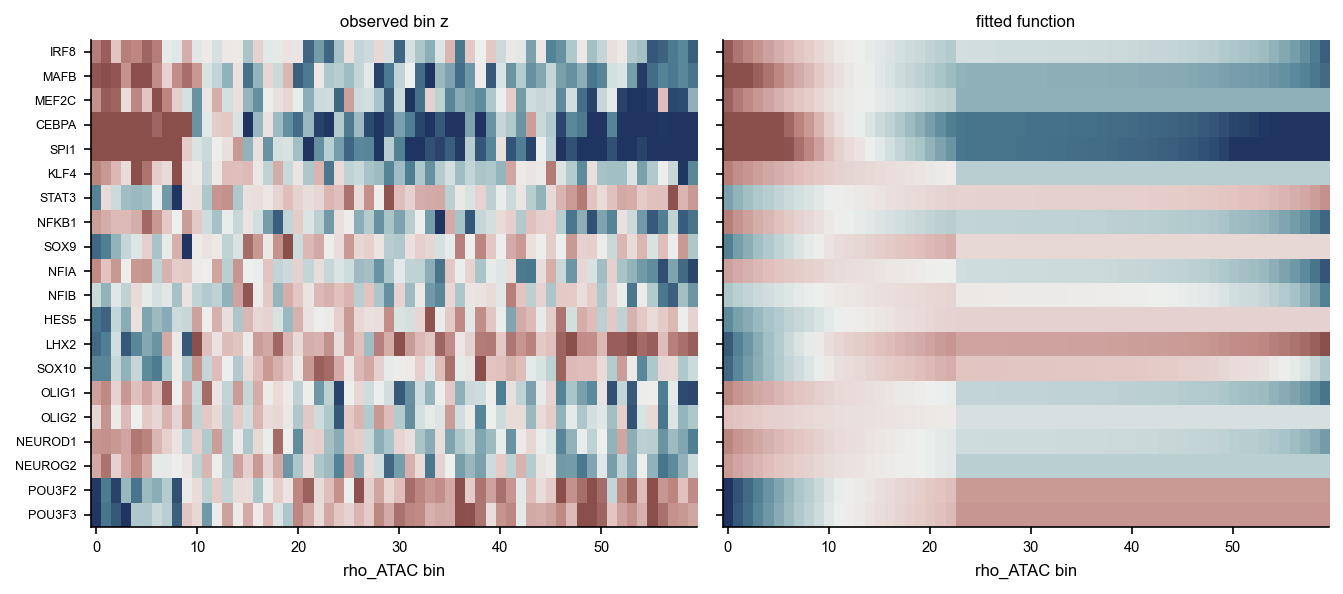

In [26]:
order_tf = [t for L in ("microglia", "stress", "astrocyte", "OL", "neuron") for t in fits["ATAC"].query("lineage == @L and R2 >= 0.15").tf]
Z = bins["ATAC"].pivot(index="tf", columns="bin", values="z").loc[order_tf]
Fz = bins["ATAC"].pivot(index="tf", columns="bin", values="fitted").loc[order_tf]
fig, ax = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for a, M_, t in ((ax[0], Z, "observed bin z"), (ax[1], Fz, "fitted function")):
    a.imshow(M_.values, aspect="auto", cmap="saturn_div", vmin=-3, vmax=3, interpolation="nearest")
    a.set(title=t, xlabel="rho_ATAC bin"); a.set_yticks(range(len(order_tf))); a.set_yticklabels(order_tf, fontsize=6)
plt.tight_layout(); plt.show()

The same deviation can be computed per spot with `deviations_matched`, which gives a spatial map of each TF rather than a function of the axis.
`log_accessibility` normalises each spot by its depth. `mechanism.smooth` averages over nearest spots for display.

per-spot z (3425, 23); max|diff| with the published tf_z_per_spot 0


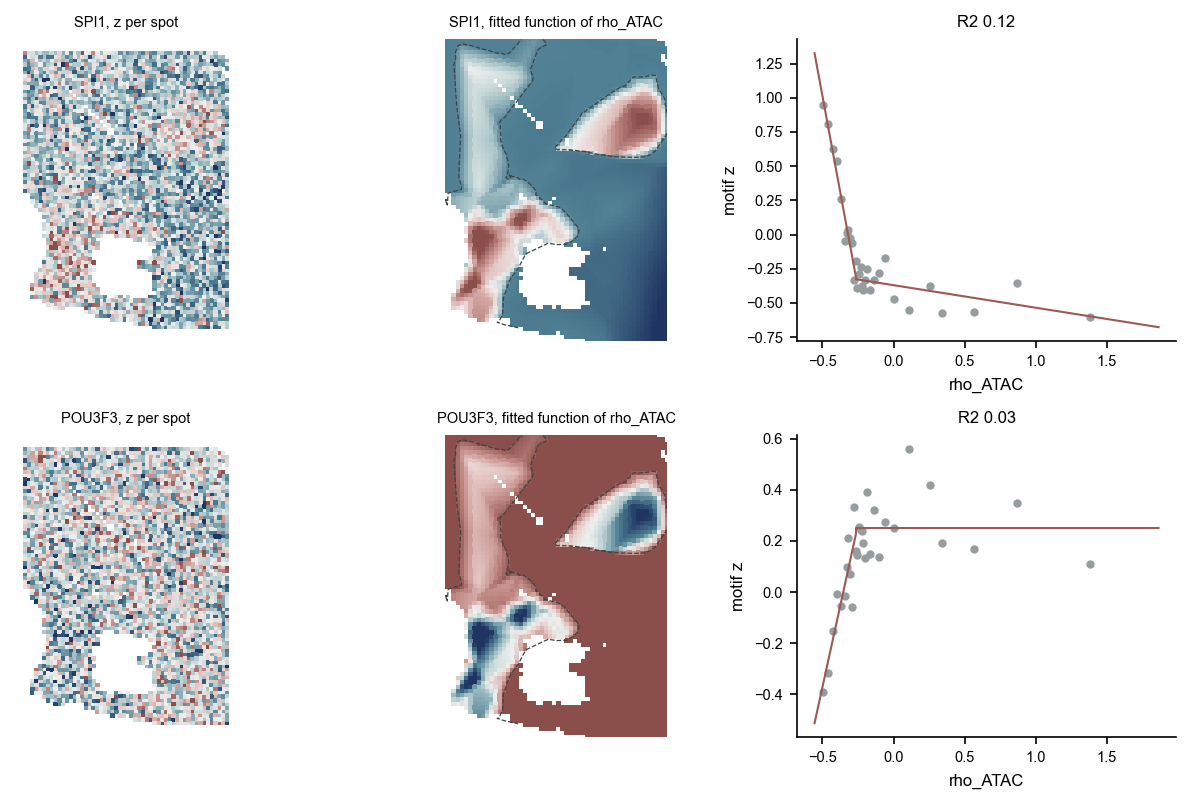

In [27]:
Z_spot = TA.deviations_matched(TA.log_accessibility(A_m, dtype=np.float32), hits, BG)
pub_z = np.load(RES / "lpc10_fov_tf_activity/tf_z_per_spot.npz", allow_pickle=True)
print(f"per-spot z {Z_spot.shape}; max|diff| with the published tf_z_per_spot {np.nanmax(np.abs(Z_spot - pub_z['z'])):.3g}")

fig, ax = plt.subplots(2, 3, figsize=(8.5, 5.4))
for r, tf in enumerate(["SPI1", "POU3F3"]):
    z = Z_spot[:, tfs.index(tf)].astype(float)
    sl, it = pw.fit_gauss(z[:, None], lab_A, d_A)
    fit = it[0][lab_A] + sl[0][lab_A] * d_A
    saturn.plotting.spatial(ax[r, 0], xy, z, f"{tf}, z per spot")
    saturn.plotting.spatial(ax[r, 1], xy, fit, f"{tf}, fitted function of rho_ATAC", contour_d=d_A, bnds=bnd_A)
    g = np.array_split(np.argsort(d_A), 30)
    ax[r, 2].plot([d_A[i].mean() for i in g], [z[i].mean() for i in g], "o", ms=3, c=ANCHOR["stone"])
    o = np.argsort(d_A); ax[r, 2].plot(d_A[o], fit[o], c=ANCHOR["rust"], lw=1)
    ax[r, 2].set(xlabel="rho_ATAC", ylabel="motif z", title=f"R2 {1 - ((z - fit) ** 2).sum() / ((z - z.mean()) ** 2).sum():.2f}")
plt.tight_layout(); plt.show()

## Genes and their cis peaks along one axis

`saturn.cis` compares genes with peaks near them. The genes are the 1,500 most-counted plus a list of programme genes with at
least 100 counts. `cis_pairs` takes, for each gene, up to 25 peaks within 1 Mb of the TSS and, as a control, up to 10 peaks at least
5 Mb away on the same chromosome. `smoothed_logcpm` builds the smoothed matrices.

In [28]:
programme = ("Trem2 Tyrobp Csf1r Cx3cr1 P2ry12 Tmem119 Irf8 Spi1 C1qa C1qb C1qc Ctss Hexb Fcrls Inpp5d Mertk Lgals3bp Apoe Cst7 Itgax Cd68 Aif1 "
             "Lyz2 Mpeg1 Laptm5 Ptprc Cd9 Man2b1 Ctsb Ctsd Ctsl Gpnmb Fth1 Spp1 Marcks Lrmda Ly86 Cd83 Syk Plek Dock8 Zeb2 Mbp Plp1 Mog Mag Mobp Cnp "
             "Cldn11 Sox10 Olig1 Olig2 Mal Ugt8a Aspa Trf Apod Ptgds Opalin Ermn Gfap Aqp4 Slc1a2 Slc1a3 Aldh1l1 S100b Sox9 Nfia Clu Vim Snap25 Syt1 "
             "Rbfox3 Nrgn Camk2a Slc17a7 Gad1 Gad2 Syp Nefl").split()
CS = saturn.cis
tg, tp = np.asarray(X.sum(0)).ravel().astype(float), np.asarray(A.sum(0)).ravel().astype(float)
gidx = {g: i for i, g in enumerate(genes)}
kg = list(np.argsort(-tg)[:1500])
kg = np.array(kg + [gidx[g] for g in programme if g in gidx and tg[gidx[g]] >= 100 and gidx[g] not in set(kg)])

tss = CS.tss_table(GTF)
cis, dist = CS.cis_pairs(kg, genes, peaks, tp, tss, distal_min=5_000_000)
need = np.unique(np.concatenate([v for v in list(cis.values()) + list(dist.values()) if len(v)]))
xy32 = xy.astype(np.float32)                                     # as the published run
G, Pk = CS.smoothed_logcpm(X, kg, xy32, 15), CS.smoothed_logcpm(A, need, xy32, 15)
gpos, ppos = {v: i for i, v in enumerate(kg)}, {v: i for i, v in enumerate(need)}
_, pmid = CS.peak_positions(peaks)
print(f"{len(cis)} genes have cis peaks; {len(need)} distinct peaks")

1499 genes have cis peaks; 16566 distinct peaks


`function_pairs` fits both features along one axis and returns a row for each gene-peak pair and domain where both slopes pass the gate.
Each row has the two slopes, whether their signs agree (`concordant`), and how alike the two whole curves are (`similarity`). Near peaks
agreeing more often than the far control would suggest that the shared direction is local to the gene. Here peaks within 25 kb agree in 58% of
pairs on rho_RNA and 54% on rho_ATAC, against 40% and 39% for the far control. The `lag_rho` column is descriptive only: it comes from
near-tied alignments, it changes when the axis changes by about 1e-16, and a small share of pairs can differ from the published table.

In [29]:
def pair_list(axis):
    return [(gpos[g], ppos[s], dict(axis=axis, kind=kind, gene=genes[g], peak=peaks[s], kb=(pmid[s] - tss[genes[g]][1]) / 1e3))
            for g, pk in cis.items() for kind, sel in (("cis", pk), ("distal", dist.get(g, np.array([], int)))) for s in sel]

pairs = pd.concat([CS.function_pairs(G, Pk, d, lab, pair_list(m)) for m, d, lab in (("RNA", d_R, lab_R), ("ATAC", d_A, lab_A))], ignore_index=True)

pub_pairs = pd.read_csv(RES / "lpc10_fov_cis_pairs/cis_function_pairs.csv")
num = ["kb", "domain", "slope_gene", "slope_peak", "speed_ratio", "n_shared", "concordant", "similarity", "lag_r"]
print(f"pairs: {pairs.shape[0]} vs published {pub_pairs.shape[0]}; same pairs in order "
      f"{(pairs.gene.values == pub_pairs.gene.values).all() and (pairs.peak.values == pub_pairs.peak.values).all()}; "
      f"max|diff| over the numeric columns except lag_rho {np.nanmax(np.abs(pairs[num].values - pub_pairs[num].values)):.3g}; "
      f"concordant equal {(pairs.concordant.values == pub_pairs.concordant.values).all()}; "
      f"lag_rho differs in {(np.abs(pairs.lag_rho.values - pub_pairs.lag_rho.values) > 1e-6).sum()} pairs")

rows = []
for m in modalities:
    s = pairs[pairs.axis == m]; c, f = s[s.kind == "cis"], s[s.kind == "distal"]
    near = c[c.kb.abs() < 25]
    rows.append(dict(axis=m, near_25kb=near.concordant.mean(), n_near=len(near), distal=f.concordant.mean(), n_distal=len(f),
                     published_near=fig2["cosign"][m]["near"], published_distal=fig2["cosign"][m]["distal"]))
pd.DataFrame(rows).round(4)

pairs: 175210 vs published 175210; same pairs in order True; max|diff| over the numeric columns except lag_rho 0; concordant equal True; lag_rho differs in 342 pairs


,axis,near_25kb,n_near,distal,n_distal,published_near,published_distal
0,RNA,0.5814,5593,0.3990,34421,0.5814,0.3990
1,ATAC,0.5412,3860,0.3883,22892,0.5412,0.3883


`gradient.rho_gradient` gives the gradient of each axis by autograd, and `gradient.spatial_gradients` gives the gradient of each feature by a
local plane. `cis.along_across_corr` then correlates gene and peak gradient components along the axis and across it, per domain. Agreement only
along the axis would mean that the axis captures it; agreement across the axis is structure a one-dimensional axis cannot represent.

In [30]:
SG = saturn.gradient
grho = SG.rho_gradient(res.model, xy).astype(np.float32)
cis_only = CS.cis_pairs(kg, genes, peaks, tp, tss)
ga_raw = np.array([g for g, pk in cis_only.items() for _ in pk]); pk_raw = np.array([s for pk in cis_only.values() for s in pk])
need2 = np.unique(pk_raw)
P2 = CS.smoothed_logcpm(A, need2, xy32, 15)
gG, gP = SG.spatial_gradients(G, xy32), SG.spatial_gradients(P2, xy32)
ga = np.array([gpos[v] for v in ga_raw]); pb = np.searchsorted(need2, pk_raw)
kb = (pmid[pk_raw] - np.array([tss[genes[i]][1] for i in ga_raw])) / 1e3

rows = []
for k, (m, lab) in enumerate((("RNA", lab_R), ("ATAC", lab_A))):
    r, frac = CS.along_across_corr(gG, gP, grho[:, k], ga, pb, lab)
    print(f"rho_{m}: {100 * frac:.0f}% of the gene gradient energy lies along the axis")
    rows += [pd.DataFrame(dict(axis=m, domain=dom, gene=genes[ga_raw], peak=peaks[pk_raw], kb=kb, r_along=np.round(ra, 4), r_across=np.round(rb, 4)))
             for dom, (ra, rb) in r.items()]
grad = pd.concat(rows, ignore_index=True)
del gG, gP

pub_grad = pd.read_csv(RES / "lpc10_fov_cis_pairs/cis_gradient_decomp.csv")
print(f"rows: {len(grad)} vs published {len(pub_grad)}; max|diff| r_along {np.abs(grad.r_along.values - pub_grad.r_along.values).max():.3g}, "
      f"r_across {np.abs(grad.r_across.values - pub_grad.r_across.values).max():.3g}")
grad.assign(dist=pd.cut(grad.kb.abs(), [0, 25, 100, 250, 500, 1000])).groupby(["axis", "dist"], observed=True)[["r_along", "r_across"]].median().round(3)

rho_RNA: 50% of the gene gradient energy lies along the axis


rho_ATAC: 50% of the gene gradient energy lies along the axis
rows: 164530 vs published 164530; max|diff| r_along 2.71e-08, r_across 1.49e-08


r_along  r_across
axis dist                          
ATAC (0, 25]        0.030     0.018
     (25, 100]      0.021     0.011
     (100, 250]     0.016     0.009
     (250, 500]     0.016     0.009
     (500, 1000]    0.015     0.010
RNA  (0, 25]        0.030     0.026
     (25, 100]      0.022     0.018
     (100, 250]     0.015     0.016
     (250, 500]     0.015     0.016
     (500, 1000]    0.016     0.017

## What the cross pathways explain

`crossterm.spot_decomposition` splits the model at each spot. `gain_RNA` is the local gain from the ATAC axis: the drop in error when the
cross term may vary, averaged over the 25 nearest spots. `gene_cross_test` compares `log1p CP10k ~ B(rho_RNA)` with
`~ B(rho_RNA) + B(rho_ATAC)` for every gene seen in at least 5% of spots, where `B` is a linear term plus hinges.

R2 RNA {'full': 0.6429219911968876, 'own_only': 0.3646844220332205}  R2 ATAC {'full': 0.6737960574948242, 'own_only': 0.4980326763551238}
gain_RNA max|diff| with the published spots 2.22e-16
4476 genes tested, 1843 at q < 0.05; published 4476, 1843
dR2_cross max|diff| 9.6e-16


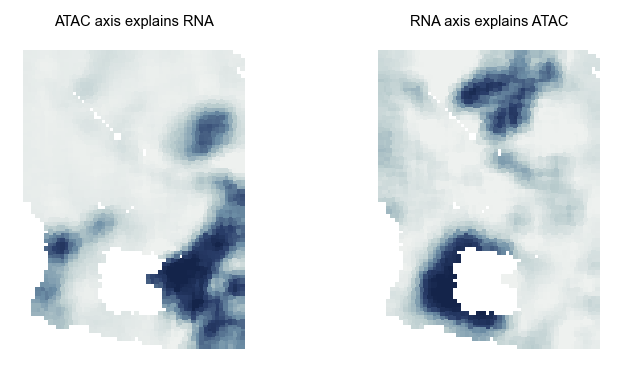

,gene,detect,R2_own,R2_own_plus_X,dR2_cross,p,q,cross_sd,cross_r_rhoX
1699,Apoe,0.958248,0.288420,0.476080,0.187660,1.512421e-222,6.769596e-219,0.685860,-0.891189
4022,Trem2,0.212555,0.143665,0.320062,0.176398,7.856303e-167,8.791203e-164,0.551167,-0.514163
1967,Ctsd,0.610511,0.254804,0.430595,0.175791,3.680528e-195,8.237021e-192,0.838852,-0.673950
1078,C1qa,0.208175,0.242550,0.405087,0.162537,7.378025e-175,1.100801e-171,0.546220,-0.540269
648,Ctsz,0.272409,0.150344,0.309939,0.159595,3.688109e-150,3.301595e-147,0.574999,-0.544739


In [31]:
CT = saturn.crossterm
T, S = CT.spot_decomposition(res.model, coords_z, xy, targets, 0, 1, (1, 1))
Gx, prof, tested = CT.gene_cross_test(X, genes, T.rho_RNA.values, T.rho_X.values)

pub_x = json.load(open(RES / "saturn_cross_term/lpc10_summary.json"))
pub_g = pd.read_csv(RES / "saturn_cross_term/lpc10_genes.csv")
pub_t = pd.read_csv(RES / "saturn_cross_term/lpc10_spots.csv", index_col=0)
print("R2 RNA", S["R2_RNA"], " R2 ATAC", S["R2_X"])
print(f"gain_RNA max|diff| with the published spots {np.abs(T.gain_RNA.values - pub_t.gain_RNA.values).max():.3g}")
print(f"{len(Gx)} genes tested, {(Gx.q < 0.05).sum()} at q < 0.05; published {pub_x['n_genes']}, {pub_x['n_cross_fdr05']}")
print(f"dR2_cross max|diff| {np.abs(Gx.set_index('gene').dR2_cross - pub_g.set_index('gene').dR2_cross.reindex(Gx.gene)).max():.3g}")

fig, ax = plt.subplots(1, 2, figsize=(5.6, 2.8))
saturn.plotting.spatial(ax[0], xy, T.gain_RNA.clip(0, None), "ATAC axis explains RNA", cmap="saturn_mono", vmin=0)
saturn.plotting.spatial(ax[1], xy, T.gain_X.clip(0, None), "RNA axis explains ATAC", cmap="saturn_mono", vmin=0)
plt.show()
Gx.head()

Here 1,843 of 4,476 genes pass q < 0.05, and Apoe, Trem2 and Ctsd have the largest gain from the ATAC axis.

`cis_windows` sums the accessibility within 50 kb of each significant gene, and `cis_concordance` correlates the cross profile of the gene with the
cross profile of its own window, against the same gene paired with random windows. `steepness_test` asks whether the gain follows the places
where the ATAC axis changes faster than the RNA axis, against rotations of the gain map. Here a gene's cross profile agrees with its own window
(mean r 0.388) more than with random windows (0.12). The steepness trend (rho 0.393) does not pass the rotation null (p 0.075).

In [32]:
sig = tested[Gx.sort_index().q.values < 0.05]
win_genes, W, _ = CT.cis_windows(A, peaks, sig, GTF)
cis_tab, cis_S = CT.cis_concordance(prof, tested, W, win_genes, T.rho_RNA.values, T.rho_X.values)
print("cis concordance", {k: round(v, 3) for k, v in cis_S.items()})
print("published      ", {k: round(v, 3) for k, v in pub_x["cis"].items()})

st = CT.steepness_test(T)["steeper_RNA"]
print(f"\nsteepness: rho {st['rho']:.3f}, rotation p {st['p_rot']:.3f}, gain by quintile {st['gain_by_quintile']}")
print(f"published: rho {pub_x['steeper_RNA']['rho']:.3f}, rotation p {pub_x['steeper_RNA']['p_rot']:.3f}, gain by quintile {pub_x['steeper_RNA']['gain_by_quintile']}")

cis concordance {'n_genes': 1709, 'mean_obs': 0.388, 'ctrl_mean': 0.12, 'ctrl_sd': 0.011, 'z': 25.223, 'p': 0.005, 'frac_pos': 0.769}
published       {'n_genes': 1709, 'mean_obs': 0.388, 'ctrl_mean': 0.12, 'ctrl_sd': 0.011, 'z': 25.223, 'p': 0.005, 'frac_pos': 0.769}



steepness: rho 0.393, rotation p 0.075, gain by quintile [0.1177, 0.1471, 0.2294, 0.316, 0.5952]
published: rho 0.393, rotation p 0.075, gain by quintile [0.1177, 0.1471, 0.2294, 0.316, 0.5952]


## Loading a saved fit

`res.save`, called right after the fit, wrote the model weights, the axes and the summary. `load_model` reads the weights back for
later analyses.

In [33]:
model = saturn.load_model(OUT / "saturn_best.pt", [Y_R.shape[1], Y_A.shape[1]])
print(np.abs(saturn.decompose(model, coords_z)[0] - res.axes).max())

0.0
